# Add tas env variable to ICON features
- **executed with runner 50!!** (if run as nbook, it computes a map of tas and saves no data)
- only needed for the 30-year dataset! 
- tried on June 2023 with ntasks = 128 => completed in null komma nix
- this notebook does:
    - input: cell_features_combined
    - load ICON ngc4008 "tas" (2m surface temperature) at zoom level 5
    - colocate cell feature centroids to temperature data
    - assign "T env" to each cell feature
    - output: save as "cell_features_combined_envfeatures"

In [1]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"


In [2]:
import warnings

# ignore general categories
for cat in [FutureWarning, RuntimeWarning, UserWarning]:
    warnings.filterwarnings("ignore", category=cat)

# ignore specific repeated messages
for msg in [
    "pyproj unable to set PROJ database path",
    "As of v1.6.0, segmentation with time length 1",
    "Using DEFAULT_SPHERICAL_EARTH_RADIUS",
    "your performance may suffer as PyTables will pickle object types that it cannot"
]:
    warnings.filterwarnings("ignore", message=msg)


import numpy as np
import xarray as xr
import os
import pandas as pd


from pathlib import Path

import glob

import sys

sys.path.append("../tools")
#from defs_application import bad_timesteps
import handle_ICON_data as ic

In [3]:
if "launcher" in sys.argv[0]: 
    interactive =True
    saveoutputfiles = False
    date = "2031-06-23-0600" 
else: 
    interactive = False
    saveoutputfiles= True
    date = sys.argv[1]

    

In [4]:
inputdir = Path(f"../output/apply_seg/apply_ICON/FULL/cell_features_combined")
filename = f"cell_features_combined_anvil_detectthres225_seg241_cell_detectthres10_seg10_{date}"

if saveoutputfiles: 
    savedir = inputdir.parent / (inputdir.name + "_envfeatures")

    
    savedir.mkdir(parents=True, exist_ok=True)


## Load features (output from segmentation)

In [5]:
file = f'{inputdir}/{filename}.h5'
data = pd.read_hdf(file, key='table')  
data = data.reset_index(drop=True)
#data

## Load icon

In [6]:
# data selection
zoom = 5 
vlist = ["tas", "crs"]

# load data
dataset = ic.open_ngc4008(zoom = zoom) 

# select timestamp and variables
dataset = ic.select_time(dataset, date)
dataset = ic.select_vars(dataset, vlist)


dataset

<xarray.Dataset> Size: 49kB
Dimensions:  (time: 1, cell: 12288, crs: 1)
Coordinates:
  * time     (time) datetime64[ns] 8B 2031-06-23T06:00:00
  * crs      (crs) float32 4B nan
Dimensions without coordinates: cell
Data variables:
    tas      (time, cell) float32 49kB dask.array<chunksize=(1, 12288), meta=np.ndarray>

In [7]:
data

,frame,idx_cell,hdim_1_cell,hdim_2_cell,num_cell,threshold_value_cell,feature_cell,time,timestr,latitude_cell,...,mean_iwp_anvil,total_iwp_anvil,max_iwp,min_tb,area_anvil,d_eq_anvil,mean_precip_anvil,total_precip_anvil,max_precip_anvil,total_dtiwp_anvil
0,0,45,173.092800,3516.962369,15,10,45,2031-06-23 06:00:00,2031-06-23 06:00:00,-12.640720,...,1.315367,134.167419,5.931857,213.266281,1.229725e+10,125.129295,4.285949,437.166840,28.936821,21.251919
1,0,49,175.701840,141.237269,6,10,49,2031-06-23 06:00:00,2031-06-23 06:00:00,-12.379816,...,0.960511,919.209106,12.699015,210.649734,1.156787e+11,383.779447,1.451055,1388.659424,60.906269,168.165649
2,0,50,175.500000,3473.000000,2,10,50,2031-06-23 06:00:00,2031-06-23 06:00:00,-12.400000,...,0.608710,89.480438,3.124005,208.968674,1.772983e+10,150.247513,0.956196,140.560867,11.492759,16.450939
3,0,53,180.320569,124.501220,17,10,53,2031-06-23 06:00:00,2031-06-23 06:00:00,-11.917943,...,0.960511,919.209106,12.699015,210.649734,1.156787e+11,383.779447,1.451055,1388.659424,60.906269,168.165649
4,0,58,184.327333,3458.191539,9,10,58,2031-06-23 06:00:00,2031-06-23 06:00:00,-11.517267,...,1.036113,183.392044,5.059847,207.146805,2.145547e+10,165.281444,3.165027,560.209839,21.988825,42.547676
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,0,1176,574.000000,3352.500000,2,10,1175,2031-06-23 06:00:00,2031-06-23 06:00:00,27.449999,...,0.647022,49.173641,3.237711,215.205978,8.313956e+09,102.886624,1.705706,129.633621,18.330389,2.932451
380,0,1179,576.000000,3351.000000,1,10,1178,2031-06-23 06:00:00,2031-06-23 06:00:00,27.650000,...,0.647022,49.173641,3.237711,215.205978,8.313956e+09,102.886624,1.705706,129.633621,18.330389,2.932451
381,0,1192,591.006501,694.558452,5,10,1191,2031-06-23 06:00:00,2031-06-23 06:00:00,29.150650,...,0.940103,482.272766,10.271354,207.350113,5.553585e+10,265.914359,0.700537,359.375488,21.683292,98.372711
382,0,1193,592.000000,699.000000,1,10,1192,2031-06-23 06:00:00,2031-06-23 06:00:00,29.250000,...,0.940103,482.272766,10.271354,207.350113,5.553585e+10,265.914359,0.700537,359.375488,21.683292,98.372711


# define co location fucntion 

In [8]:
def colocate_tas_at_cell_centroids(cells_df, dataset, zoom=5, var="tas"):
    """
    Look up 2m temperature at cell centroids directly on HEALPix grid.
    Avoids lossy regridding to lat/lon.
    
    Parameters
    ----------
    cells_df : pd.DataFrame
        Cell feature dataframe with latitude_cell, longitude_cell columns
    dataset : xr.Dataset
        ICON ngc4008 dataset (HEALPix, already time-selected)
    zoom : int
        HEALPix zoom level (nside = 2**zoom)
    var : str
        Variable name to look up
    
    Returns
    -------
    cells_df : pd.DataFrame
        Input dataframe with new column f"{var}_cell"
    """
    import healpy as hp
    nside = 2 ** zoom
    
    # Get HEALPix pixel indices for each cell centroid
    # healpy expects co-latitude (theta) and longitude (phi) in radians
    lats = cells_df["latitude_cell"].values
    lons = cells_df["longitude_cell"].values % 360  # modulo => so that 0-360 lons
    
    theta = np.radians(90 - lats)   # colatitude
    phi   = np.radians(lons)
    
    pix_ids = hp.ang2pix(nside, theta, phi, nest=True)  # nest=True for ICON
    
    # Extract tas values at those pixels
    tas_vals = dataset[var].squeeze().values[pix_ids]
    #tas_vals = dataset[var].values[pix_ids]
    
    cells_df = cells_df.copy()
    cells_df[f"{var}_cell"] = tas_vals
    
    return cells_df

## determine tas at features and as tas_env 

In [9]:
cells_with_tas = colocate_tas_at_cell_centroids(data, dataset, zoom=zoom)
#cells_with_tas

# save features

In [10]:
# save features
if saveoutputfiles:
    cells_with_tas.to_hdf(
        savedir / f'{filename}-envfeatures.h5',
        key='table', mode='w'
    )
    
    print(f'cell features combined with anvil properties saved for {date}')



# resample to IMERG AND Plot (only out of curiosity, to check if data is ok)

In [11]:
## colocate the ICON data with OBS
# resample to Imerg grid
if interactive: 
    tas= ic.resample_to_lon_lat(dataset, "tas", zoom= zoom,to_imerg = True)

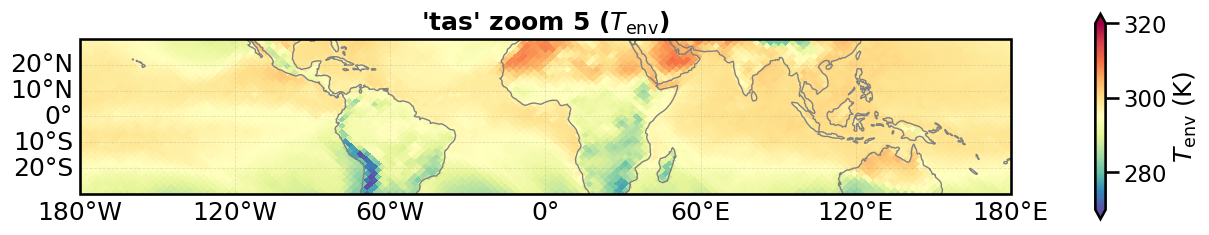

In [12]:
if interactive: 
    # invert colorbar! and set scaling correct
    def summarized_domain_plot(tas, title, domain=[-180,180,-30,30],
                               tas_vmin=200, tas_vmax=300):
        import seaborn as sns
        import matplotlib.pyplot as plt
        import cartopy.crs as ccrs
        import plots_mapping as pm
        
        sns.set_context("talk")
        fig, ax = plt.subplots(
            1, 1,
            figsize=(12, 7),
            subplot_kw={"projection": ccrs.PlateCarree()},
            constrained_layout=True
        )
    
        ax = pm.domain_plot_tas(tas, domain=domain, left_grid_label=True, bottom_grid_label=True,
                       title=r"'tas' zoom 5 ($T_{\text{env}}$)",
                       vmin=tas_vmin, vmax=tas_vmax,
                       fig=fig, ax=ax,shrink = 0.3)
        
    
        fig.suptitle(title, fontweight="bold")
    
        return fig
        
    tas.attrs["short_name"] = r"$T_{\text{env}}$"
    
    zoom5 = summarized_domain_plot(tas = tas, title = "", domain=[-180,180,-30,30],
                                   tas_vmin=270, tas_vmax=320)

    zoom5.savefig(f"../output/plots/tas_input_image_example_{date}.pdf")